## JEV performance analysis

Compares JEV predictions (`jev_classification.json`) against manual labels (`manual_classification.json`).

Metrics: overall accuracy, per-class accuracy, recall, precision, and confusion matrix.

In [124]:
import json

MANUAL_PATH = "manual_classification.json"
JEV_PATH = "jev_classification.json"

with open(MANUAL_PATH, encoding="utf-8") as f:
    manual = {item["text"]: item["classification"] for item in json.load(f)}

with open(JEV_PATH, encoding="utf-8") as f:
    jev = {item["text"]: item["classification"] for item in json.load(f)}

texts = [text for text in manual if text in jev]
y_true = [manual[text] for text in texts]
y_pred = [jev[text] for text in texts]

print(f"manual: {len(manual)} | jev: {len(jev)} | evaluated: {len(texts)}")

manual: 1000 | jev: 1000 | evaluated: 1000


### Overall accuracy

In [125]:
correct = sum(t == p for t, p in zip(y_true, y_pred))
accuracy = correct / len(texts)

print(f"Correct:  {correct}/{len(texts)}")
print(f"Accuracy: {accuracy:.4f}")

Correct:  842/1000
Accuracy: 0.8420


### Confusion matrix

Rows = manual (truth), columns = JEV (prediction).

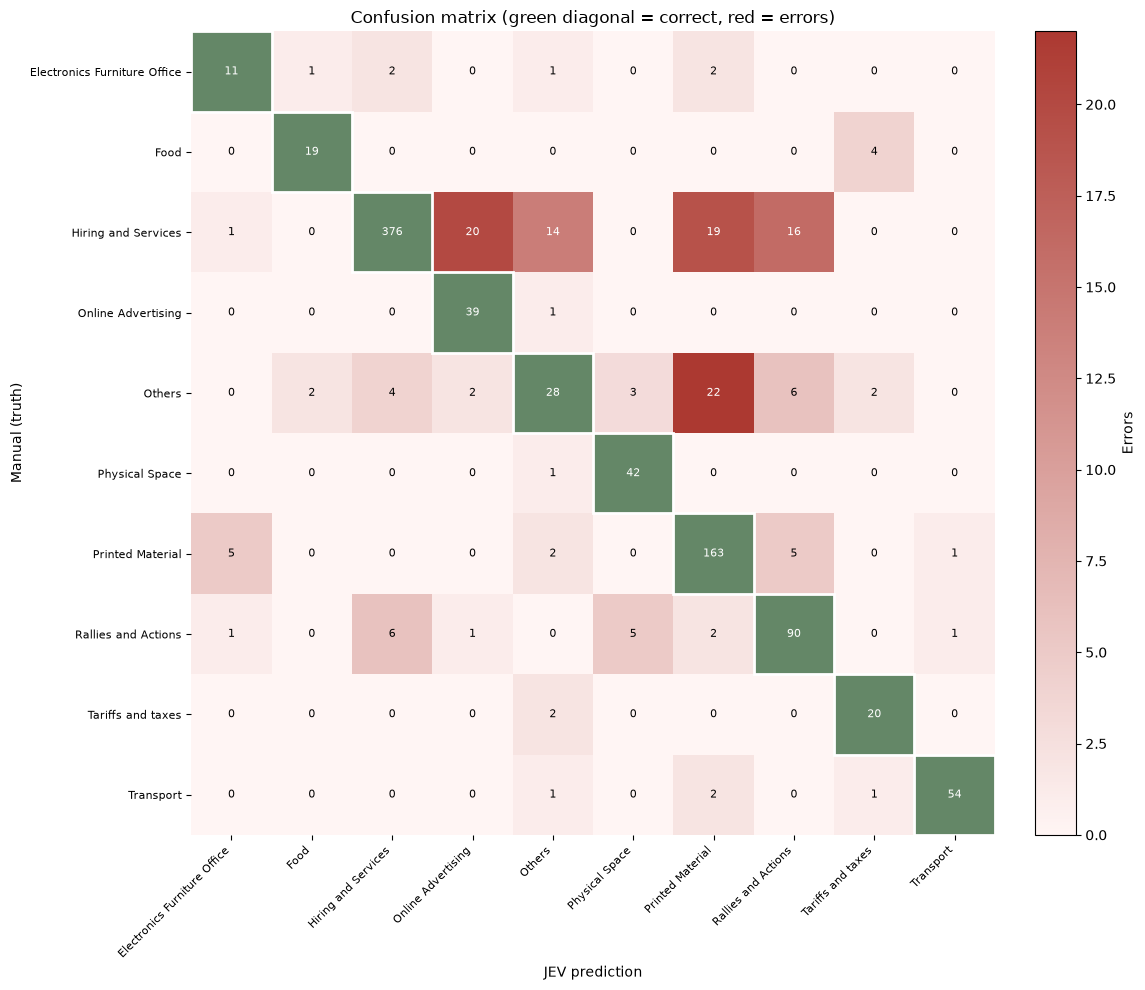

In [126]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

labels = sorted(set(y_true) | set(y_pred))

# keep the dict form for the metrics cells
matrix = {t: {p: 0 for p in labels} for t in labels}
for t, p in zip(y_true, y_pred):
    matrix[t][p] += 1

# numpy view for the heatmap
m = np.array([[matrix[t][p] for p in labels] for t in labels])

# off-diagonal cells share a red scale; the diagonal gets a single flat color
off = np.where(np.eye(len(labels), dtype=bool), np.nan, m)
red_cmap = LinearSegmentedColormap.from_list("reds", ["#fff5f4", "#AC3931"])
red_cmap.set_bad("#648767")

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(off, cmap=red_cmap, vmin=0, vmax=np.nanmax(off))

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels, fontsize=8)

ax.set_xlabel("JEV prediction")
ax.set_ylabel("Manual (truth)")
ax.set_title("Confusion matrix (green diagonal = correct, red = errors)")

threshold = np.nanmax(off) / 2
for i in range(len(labels)):
    for j in range(len(labels)):
        value = m[i, j]
        if i == j:
            color = "white"
        else:
            color = "white" if value > threshold else "black"
        ax.text(j, i, str(value), ha="center", va="center", fontsize=8, color=color)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Errors")

for spine in ax.spines.values():
    spine.set_visible(False)

# draw cell borders on the diagonal so the flat-green cells read clearly
for i in range(len(labels)):
    ax.add_patch(plt.Rectangle((i - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="white", linewidth=2))

fig.tight_layout()
fig.savefig("confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

### Per-class accuracy, precision and recall

- **precision** = TP / (TP + FP): of everything JEV labeled as class X, how much was right.
- **recall** = TP / (TP + FN): of everything that is truly class X, how much JEV found.
- **accuracy** = TP / (TP + FP + FN): how often JEV is right when it either predicts or should predict class X.

In [127]:
print(f"{'class':<35}{'prec':>8}{'recall':>8}{'acc':>8}{'support':>9}{'tp':>6}{'fp':>6}{'fn':>6}")

metrics = []
for label in labels:
    tp = matrix[label][label]
    fp = sum(matrix[t][label] for t in labels if t != label)
    fn = sum(matrix[label][p] for p in labels if p != label)

    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    class_acc = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0
    support = tp + fn

    metrics.append((label, precision, recall, class_acc, support, tp, fp, fn))
    print(f"{label:<35}{precision:>8.3f}{recall:>8.3f}{class_acc:>8.3f}{support:>9}{tp:>6}{fp:>6}{fn:>6}")

class                                  prec  recall     acc  support    tp    fp    fn
Electronics Furniture Office          0.611   0.647   0.458       17    11     7     6
Food                                  0.864   0.826   0.731       23    19     3     4
Hiring and Services                   0.969   0.843   0.821      446   376    12    70
Online Advertising                    0.629   0.975   0.619       40    39    23     1
Others                                0.560   0.406   0.308       69    28    22    41
Physical Space                        0.840   0.977   0.824       43    42     8     1
Printed Material                      0.776   0.926   0.731      176   163    47    13
Rallies and Actions                   0.769   0.849   0.677      106    90    27    16
Tariffs and taxes                     0.741   0.909   0.690       22    20     7     2
Transport                             0.964   0.931   0.900       58    54     2     4


### Macro and weighted averages

In [128]:
n = len(labels)
total_support = sum(m[4] for m in metrics)

macro_precision = sum(m[1] for m in metrics) / n
macro_recall = sum(m[2] for m in metrics) / n
macro_accuracy = sum(m[3] for m in metrics) / n

weighted_precision = sum(m[1] * m[4] for m in metrics) / total_support
weighted_recall = sum(m[2] * m[4] for m in metrics) / total_support

print(f"{'macro':<35}{macro_precision:>8.3f}{macro_recall:>8.3f}{macro_accuracy:>8.3f}{total_support:>9}")
print(f"{'weighted':<35}{weighted_precision:>8.3f}{weighted_recall:>8.3f}{accuracy:>8.3f}{total_support:>9}")

macro                                 0.772   0.829   0.676     1000
weighted                              0.853   0.842   0.842     1000


### Worst confusions

Most frequent manual -> JEV mistakes.

In [129]:
mistakes = [
    {"count": matrix[t][p], "truth": t, "predicted": p}
    for t in labels for p in labels
    if t != p and matrix[t][p] > 0
]
mistakes.sort(key=lambda m: m["count"], reverse=True)

for m in mistakes[:15]:
    print(f"{m['count']:>4}  {m['truth']:<32} -> {m['predicted']}")

  22  Others                           -> Printed Material
  20  Hiring and Services              -> Online Advertising
  19  Hiring and Services              -> Printed Material
  16  Hiring and Services              -> Rallies and Actions
  14  Hiring and Services              -> Others
   6  Others                           -> Rallies and Actions
   6  Rallies and Actions              -> Hiring and Services
   5  Printed Material                 -> Electronics Furniture Office
   5  Printed Material                 -> Rallies and Actions
   5  Rallies and Actions              -> Physical Space
   4  Food                             -> Tariffs and taxes
   4  Others                           -> Hiring and Services
   3  Others                           -> Physical Space
   2  Electronics Furniture Office     -> Hiring and Services
   2  Electronics Furniture Office     -> Printed Material


### Save errors

Every record where the JEV prediction differs from the manual label.

In [130]:
errors = [
    {
        "text": text,
        "manual": manual[text],
        "jev": jev[text],
    }
    for text in texts
    if manual[text] != jev[text]
]

with open("errors.json", "w", encoding="utf-8") as f:
    json.dump(errors, f, indent=2, ensure_ascii=False)

print(f"Saved {len(errors)} errors -> errors.json")

Saved 158 errors -> errors.json


### Accuracy by confidence threshold

For each class, accuracy among records with confidence >= threshold.
One chart per class, thresholds from 0.10 up to 0.90 step 0.10, plus 0.95 and 0.99.

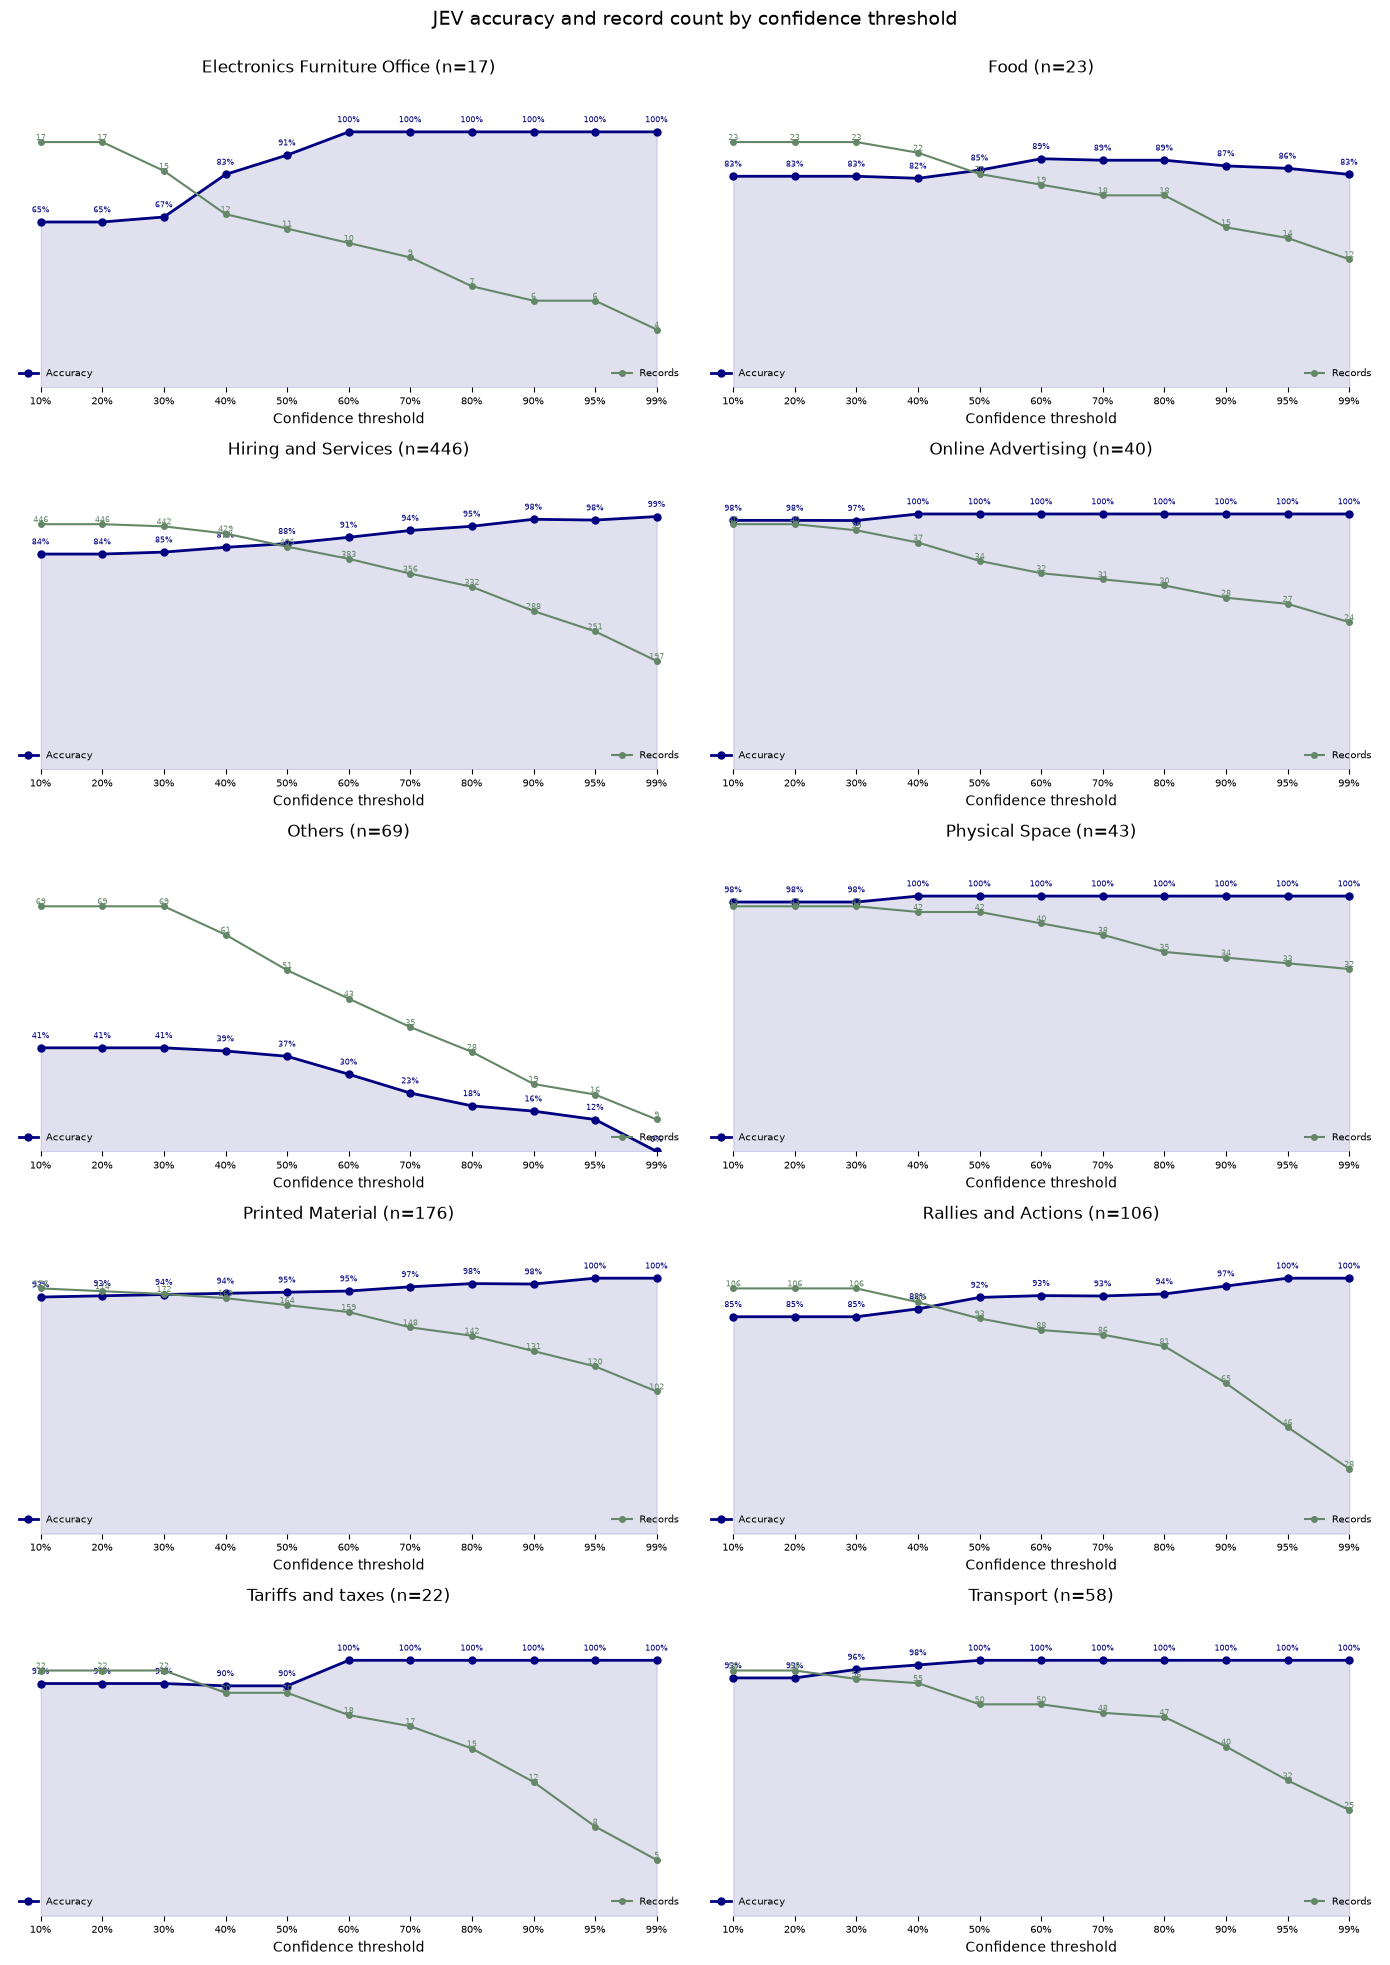

In [131]:
import matplotlib.pyplot as plt

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
confidences = {item["text"]: item["confidence"] for item in json.load(open(JEV_PATH, encoding="utf-8"))}
classes = sorted(set(y_true))

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

x = list(range(len(thresholds)))
xticklabels = [f"{int(round(t * 100))}%" for t in thresholds]

for ax, klass in zip(axes.flat, classes):
    rates = []
    counts = []
    for thr in thresholds:
        subset = [
            text for text in texts
            if manual[text] == klass and confidences[text] >= thr
        ]
        hits = sum(1 for text in subset if jev[text] == klass)
        rates.append(hits / len(subset) if subset else 0.0)
        counts.append(len(subset))

    ax2 = ax.twinx()

    ax.fill_between(x, rates, color="navy", alpha=0.12)
    ax.plot(x, rates, color="navy", linewidth=2, marker="o", markersize=5, label="Accuracy")
    ax2.plot(x, counts, color="#648767", linewidth=1.5, marker="o", markersize=4, label="Records")

    for xi, rate in zip(x, rates):
        ax.text(xi, rate + 0.03, f"{rate * 100:.0f}%", ha="center", va="bottom", fontsize=6, color="navy")

    for xi, count in zip(x, counts):
        ax2.text(xi, count, str(count), ha="center", va="bottom", fontsize=6, color="#648767")

    ax.set_xticks(x)
    ax.set_xticklabels(xticklabels, fontsize=7)
    ax.set_title(f"{klass} (n={sum(1 for t in texts if manual[t] == klass)})")
    ax.set_xlabel("Confidence threshold")

    ax.set_ylim(0, 1.2)
    ax2.set_ylim(0, max(1, max(counts)) * 1.25)

    ax.set_yticks([])
    ax2.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)
    for spine in ax2.spines.values():
        spine.set_visible(False)

    ax.legend(loc="lower left", fontsize=7, frameon=False)
    ax2.legend(loc="lower right", fontsize=7, frameon=False)

fig.suptitle("JEV accuracy and record count by confidence threshold", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig("accuracy_by_confidence.png", dpi=120, bbox_inches="tight")
plt.show()

### Correct vs wrong by confidence threshold

One panel per class. For each confidence threshold, the bar stacks errors (red, base)
and correct predictions (green, top) among that class's records; accuracy is written above.

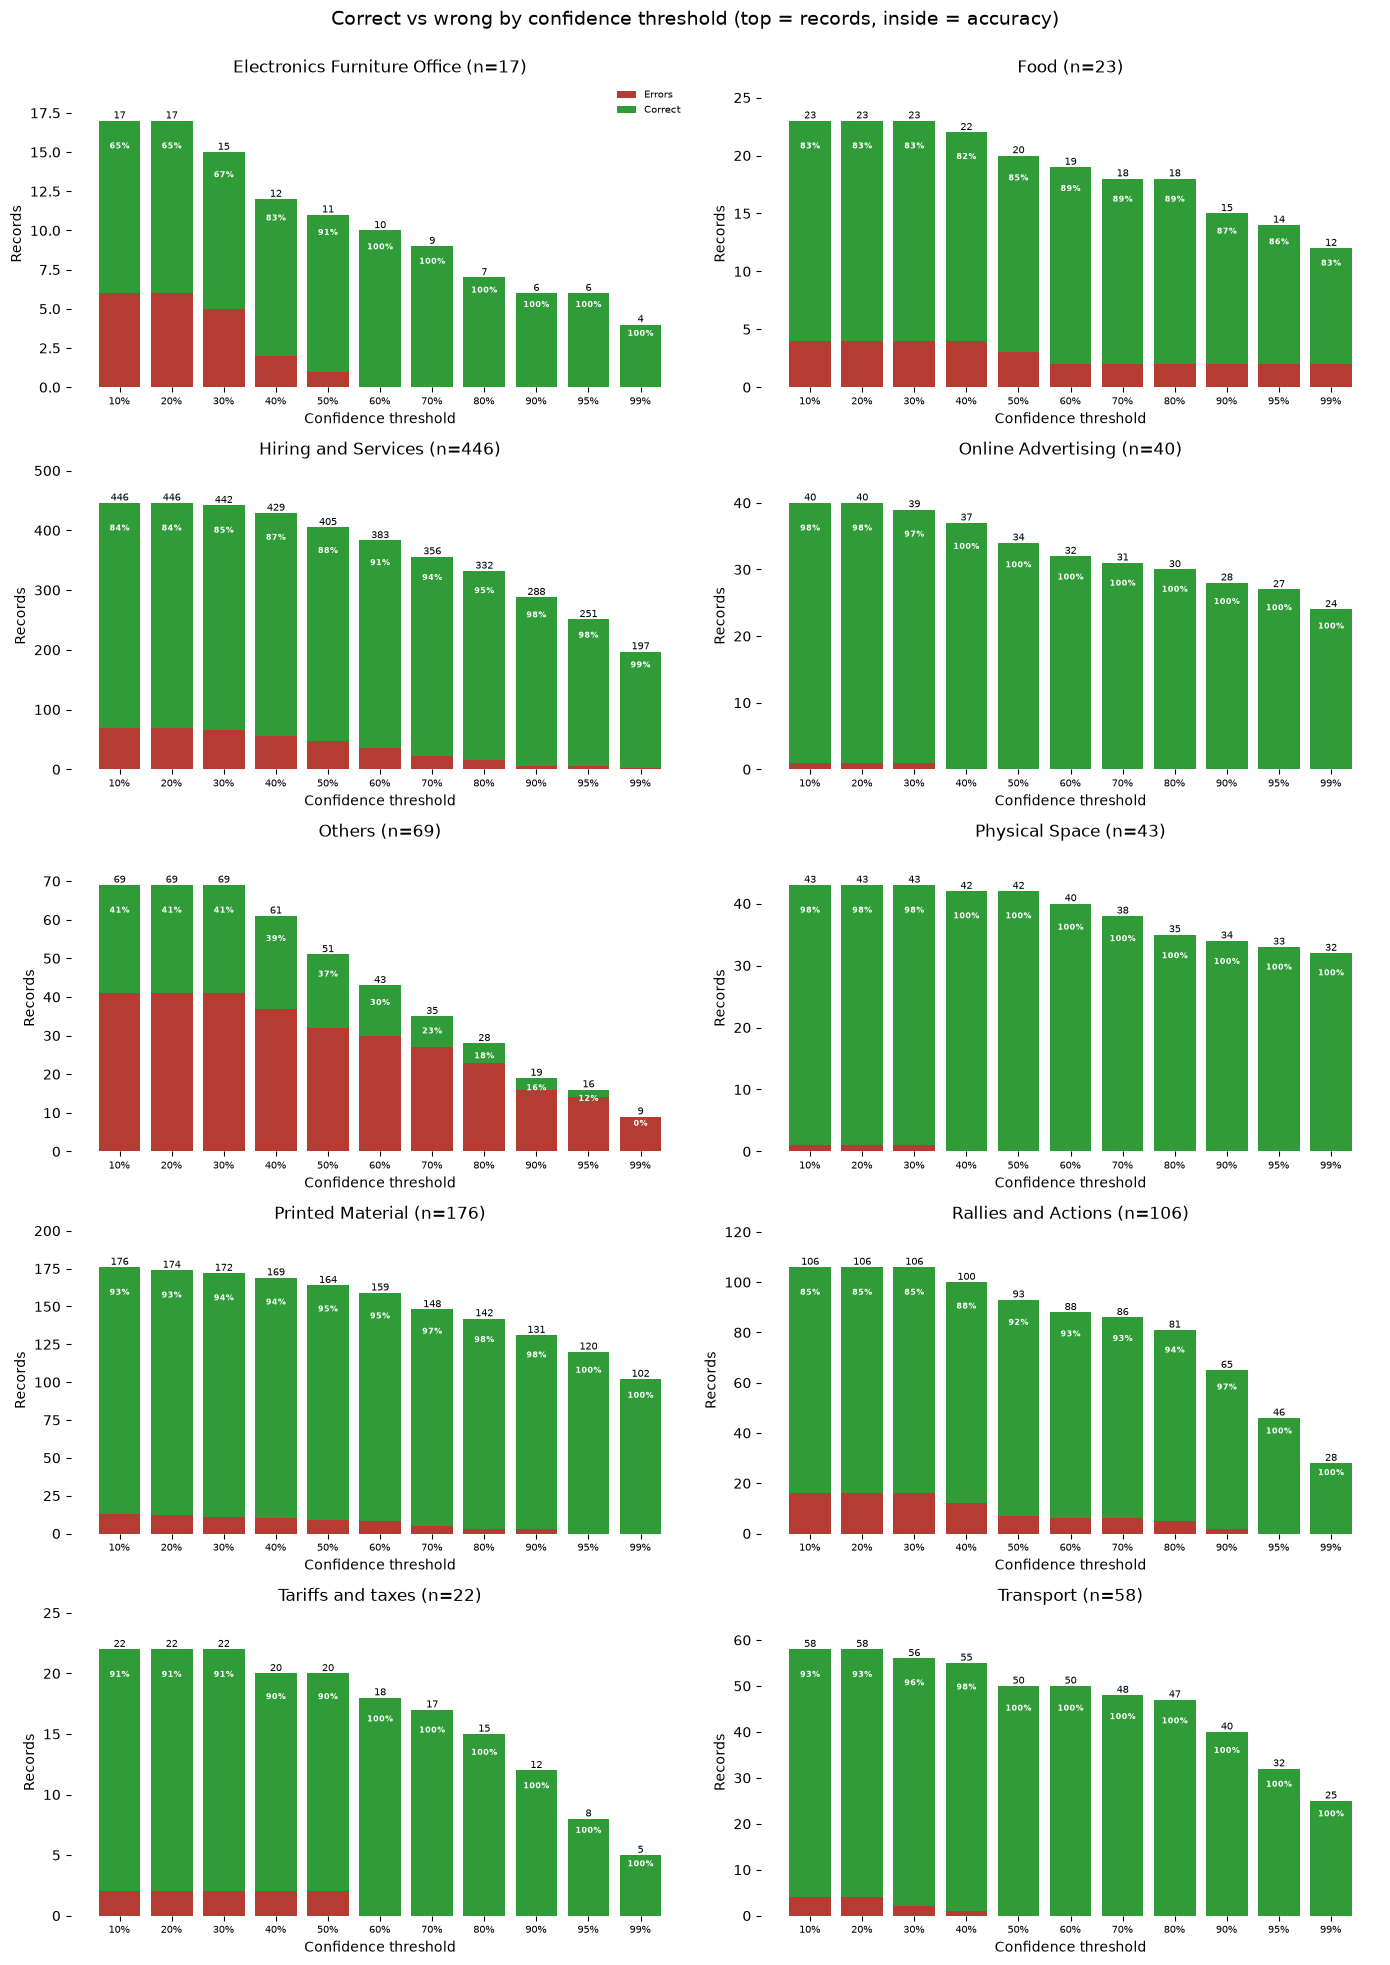

In [132]:
import matplotlib.pyplot as plt

thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99]
confidences = {item["text"]: item["confidence"] for item in json.load(open(JEV_PATH, encoding="utf-8"))}
classes = sorted(set(y_true))

GREEN = "#2F9C38"
RED = "#B53C33"

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

x = list(range(len(thresholds)))
xticklabels = [f"{int(round(t * 100))}%" for t in thresholds]

for ax, klass in zip(axes.flat, classes):
    corrects = []
    errors = []
    for thr in thresholds:
        subset = [
            text for text in texts
            if manual[text] == klass and confidences[text] >= thr
        ]
        hits = sum(1 for text in subset if jev[text] == klass)
        corrects.append(hits)
        errors.append(len(subset) - hits)

    ax.bar(x, errors, color=RED, label="Errors")
    ax.bar(x, corrects, bottom=errors, color=GREEN, label="Correct")

    for xi, (err, corr) in enumerate(zip(errors, corrects)):
        total = err + corr
        acc = corr / total if total else 0.0

        # record count above the bar
        ax.text(xi, total, str(total), ha="center", va="bottom", fontsize=7)

        # accuracy just inside the bar, white text
        if total:
            ax.text(xi, total - total * 0.08, f"{acc * 100:.0f}%", ha="center", va="top",
                    fontsize=6, color="white", fontweight="bold")

    ax.set_xticks(x)
    ax.set_xticklabels(xticklabels, fontsize=7)
    ax.set_title(f"{klass} (n={sum(1 for t in texts if manual[t] == klass)})")
    ax.set_xlabel("Confidence threshold")
    ax.set_ylabel("Records")
    ax.set_ylim(0, max(1, max(c + e for c, e in zip(corrects, errors))) * 1.15)

    for spine in ax.spines.values():
        spine.set_visible(False)

axes.flat[0].legend(fontsize=7, frameon=False)

fig.suptitle("Correct vs wrong by confidence threshold (top = records, inside = accuracy)", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.98])
fig.savefig("correct_vs_wrong.png", dpi=120, bbox_inches="tight")
plt.show()